# CCN figure

The purpose of this notebook is to make a combined figure for the CCN abstract in order to free up space.

## Imports

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from adaptive_bottleneck.utils import load_plot_config

load_plot_config()

## Config

In [2]:
LABEL_MODES  = ("feature", "position")
MODE_TITLES  = {"feature": "Feature", "position": "Position"}
ATTN_KIND    = "softmax"   # adjust as needed
shade        = "sem"

FIXED_RESULTS_PATH     = "../../data/context_identification_full_sweep.json"
ONLINE_RESULTS_PATH    = "../../data/online_gamma_20seeds_sweep.json"
POS_CODES_RESULTS_PATH = "../../data/pos_codes_comparison_sweep.json"
SAVE_PATH              = "../results/summary_figure.pdf"

EPOCH_START = 0
EPOCH_END   = 2500  # set to None for all epochs

# Positional-codes comparison conditions (mirrors pos_codes_comparison_sweep.py)
POS_CONDITIONS = ("adaptive", "adaptive_pos", "attn_pos")
POS_CONDITION_LABELS = {
    "adaptive":     "Adaptive (no pos codes)",
    "adaptive_pos": "Adaptive + pos codes",
    "attn_pos":     "Attention + pos codes",
}
POS_CONDITION_COLORS = {
    "adaptive":     plt.cm.plasma(0.2),
    "adaptive_pos": plt.cm.plasma(0.55),
    "attn_pos":     plt.cm.plasma(0.85),
}
# Row/col labels for the standalone per-condition trajectories figure
# (mirrors plot_pos_codes_comparison_results.py: plot_accuracy)
POS_ROW_LABELS = {
    "adaptive":     "ARCA",
    "adaptive_pos": "ARCA (pos. codes)",
    "attn_pos":     "Cross attention (pos. codes)",
}
POS_COL_TITLES = {"feature": "Feature label", "position": "Positional label"}

## Helpers

In [3]:
def load_json(path):
    with open(path) as f:
        return json.load(f)

def collect_curves(seed_dict, key):
    return np.stack(
        [np.array(hist[key]) for hist in seed_dict.values()], axis=0
    )

def mean_err(curves, shade="sem"):
    mean = curves.mean(axis=0)
    std  = curves.std(axis=0, ddof=1) if curves.shape[0] > 1 else np.zeros_like(mean)
    err  = std / np.sqrt(curves.shape[0]) if shade == "sem" else std
    return mean, err

def plot_individual_trajectories(ax, epochs, curves, color):
    """Draw one faint line per seed (mirrors plot_pos_codes_comparison_results.py)."""
    for traj in curves:
        ax.plot(epochs, traj, color=color, linewidth=0.4, alpha=0.3)

def plot_mean_sem_curve(ax, epochs, curves, color, shade="sem"):
    mean, err = mean_err(curves, shade)
    ax.plot(epochs, mean, color=color, linewidth=1.5)
    ax.fill_between(epochs, mean - err, mean + err, color=color, alpha=0.15)

## Figure

In [4]:
def fill_fixed_gamma_col(axes_col, results, gammas, shade="sem",
                          label_fontsize=8, tick_fontsize=8):
    """Fill a 2-panel column with fixed-gamma sweep accuracy curves."""
    cmap = cm.plasma
    norm = Normalize(vmin=min(gammas), vmax=max(gammas))

    for ax, lm in zip(axes_col, LABEL_MODES):
        for g in gammas:
            g_key     = str(g)
            seed_dict = results[lm][ATTN_KIND][g_key]
            curves    = np.stack(
                [np.array(hist["test_acc"], dtype=float)
                 for hist in seed_dict.values()], axis=0
            )
            m, e  = mean_err(curves, shade)
            epochs = np.arange(curves.shape[1])
            color  = cmap(norm(g))
            ax.plot(epochs, m, color=color, linewidth=1.5, alpha=0.95)
            ax.fill_between(epochs, m - e, m + e, color=color, alpha=0.20)

        ax.set_ylabel(f"{MODE_TITLES[lm]} test acc", fontsize=label_fontsize)
        ax.set_ylim(0.0, 1.05)
        ax.grid(alpha=0.2)
        ax.tick_params(axis="both", labelsize=tick_fontsize)

    axes_col[-1].set_xlabel("Epoch", fontsize=label_fontsize)
    return cmap, norm   # returned so caller can draw colorbar


def fill_online_gamma_col(axes_col, results,
                           epoch_start=0, epoch_end=None, shade="sem",
                           label_fontsize=8, legend_fontsize=7, tick_fontsize=8):
    """Fill a 2-panel column with dual-axis accuracy + gamma trajectory."""
    acc_color = plt.cm.plasma(0.3)
    gam_color = plt.cm.plasma(0.75)

    twin_axes = []
    for ax_acc, mode in zip(axes_col, LABEL_MODES):
        acc_curves = collect_curves(results[mode], "test_acc")
        gam_curves = collect_curves(results[mode], "gamma")

        n_epochs = acc_curves.shape[1]
        end      = epoch_end if epoch_end is not None else n_epochs
        sl       = slice(epoch_start, end)
        epochs   = np.arange(epoch_start, end)

        acc_m, acc_e = mean_err(acc_curves[:, sl], shade)
        gam_m, gam_e = mean_err(gam_curves[:, sl], shade)

        # left axis — accuracy
        ax_acc.plot(epochs, acc_m, color=acc_color, linewidth=1.5, label="Test acc")
        ax_acc.fill_between(epochs, acc_m - acc_e, acc_m + acc_e,
                            color=acc_color, alpha=0.20)
        ax_acc.set_ylim(0.0, 1.05)
        ax_acc.set_ylabel(f"{MODE_TITLES[mode]} test acc", fontsize=label_fontsize, color=acc_color)
        ax_acc.tick_params(axis="y", labelcolor=acc_color, labelsize=tick_fontsize)
        ax_acc.tick_params(axis="x", labelsize=tick_fontsize)
        ax_acc.grid(alpha=0.2)

        # right axis — gamma
        ax_gam = ax_acc.twinx()
        ax_gam.plot(epochs, gam_m, color=gam_color, linewidth=1.5,
                    linestyle="--", label="$\\gamma$")
        ax_gam.fill_between(epochs, gam_m - gam_e, gam_m + gam_e,
                            color=gam_color, alpha=0.15)
        ax_gam.set_ylim(-0.05, 1.05)
        ax_gam.set_ylabel("$\\gamma$", fontsize=label_fontsize, color=gam_color)
        ax_gam.tick_params(axis="y", labelcolor=gam_color, labelsize=tick_fontsize)

        lines  = ax_acc.get_lines() + ax_gam.get_lines()
        labels = [l.get_label() for l in lines]
        ax_acc.legend(lines, labels, fontsize=legend_fontsize, loc="center right", frameon=False)

        twin_axes.append(ax_gam)

    axes_col[-1].set_xlabel("Epoch", fontsize=label_fontsize)
    return twin_axes


def fill_pos_codes_col(axes_col, results, shade="sem",
                        label_fontsize=8, legend_fontsize=6, tick_fontsize=8):
    """Fill a 2-panel column with overlaid positional-codes comparison accuracy curves
    (one line per condition, mirrors plot_pos_codes_comparison_results.py)."""
    for ax, lm in zip(axes_col, LABEL_MODES):
        for cond in POS_CONDITIONS:
            seed_dict = results[cond][lm]
            curves    = collect_curves(seed_dict, "test_acc")
            epochs    = np.arange(curves.shape[1])
            m, e      = mean_err(curves, shade)
            color     = POS_CONDITION_COLORS[cond]
            ax.plot(epochs, m, color=color, linewidth=1.5, label=POS_CONDITION_LABELS[cond])
            ax.fill_between(epochs, m - e, m + e, color=color, alpha=0.20)

        ax.set_ylabel(f"{MODE_TITLES[lm]} test acc", fontsize=label_fontsize)
        ax.set_ylim(0.0, 1.05)
        ax.grid(alpha=0.2)
        ax.tick_params(axis="both", labelsize=tick_fontsize)

    axes_col[-1].set_xlabel("Epoch", fontsize=label_fontsize)
    axes_col[0].legend(fontsize=legend_fontsize, loc="lower right")


# ── Main figure ───────────────────────────────────────────────────────────────
def make_summary_figure(
    fixed_results_path     = FIXED_RESULTS_PATH,
    online_results_path    = ONLINE_RESULTS_PATH,
    pos_codes_results_path = POS_CODES_RESULTS_PATH,
    save_path               = SAVE_PATH,
    gammas                  = None,   # list of gamma values in fixed sweep
    epoch_start              = EPOCH_START,
    epoch_end                = EPOCH_END,
    shade                    = "sem",
    label_fontsize           = 8,
    legend_fontsize          = 7,
    tick_fontsize            = 8,
):
    fixed_results     = load_json(fixed_results_path)
    online_results    = load_json(online_results_path)
    pos_codes_results = load_json(pos_codes_results_path)

    if gammas is None:
        # infer gamma values from the first label mode
        first_lm = LABEL_MODES[0]
        gammas = sorted(float(k) for k in fixed_results[first_lm][ATTN_KIND].keys())

    # ── Grid: 2 rows × 4 cols, width_ratios gives space to cols 1-3
    #    col 0 is intentionally left blank for Illustrator
    fig, axes = plt.subplots(
        2, 4,
        figsize=(15.5, 3.5),
        gridspec_kw={"width_ratios": [2, 1.35, 1, 1.3], "hspace": 0.45, "wspace": 0.4},
    )

    # ── Col 0: blank — keep axes alive (preserves grid space) but strip decorations
    for ax in axes[:, 0]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    # ── Col 1: fixed-gamma sweep ─────────────────────────────────────────────
    cmap, norm = fill_fixed_gamma_col(
        axes[:, 1], fixed_results, gammas, shade,
        label_fontsize=label_fontsize, tick_fontsize=tick_fontsize,
    )

    # colorbar anchored to col 1 only
    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes[:, 1], location="right", pad=0.04, shrink=0.85)
    cbar.set_label("$\\gamma$", fontsize=label_fontsize)
    cbar.ax.tick_params(labelsize=tick_fontsize)

    # ── Col 2: online gamma ──────────────────────────────────────────────────
    fill_online_gamma_col(
        axes[:, 2], online_results, epoch_start, epoch_end, shade,
        label_fontsize=label_fontsize, legend_fontsize=legend_fontsize, tick_fontsize=tick_fontsize,
    )

    # ── Col 3: positional codes comparison ────────────────────────────────────
    fill_pos_codes_col(
        axes[:, 3], pos_codes_results, shade,
        label_fontsize=label_fontsize, legend_fontsize=legend_fontsize, tick_fontsize=tick_fontsize,
    )

    # ── Column headers ───────────────────────────────────────────────────────
    col_titles = [
        "(A) Task schematic",
        "(B) Fixed $\\gamma$ sweep",
        "(C) Learnable $\\gamma$",
        "(D) Positional codes",
    ]
    for col, title in enumerate(col_titles):
        axes[0, col].set_visible(True)   # briefly re-enable col 0 for title
        axes[0, col].set_title(title, fontsize=10, fontweight="bold", pad=14)

    err_label = "SEM" if shade == "sem" else "STD"

    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Saved → {save_path}")
    plt.show()

Saved → ../results/summary_figure.pdf


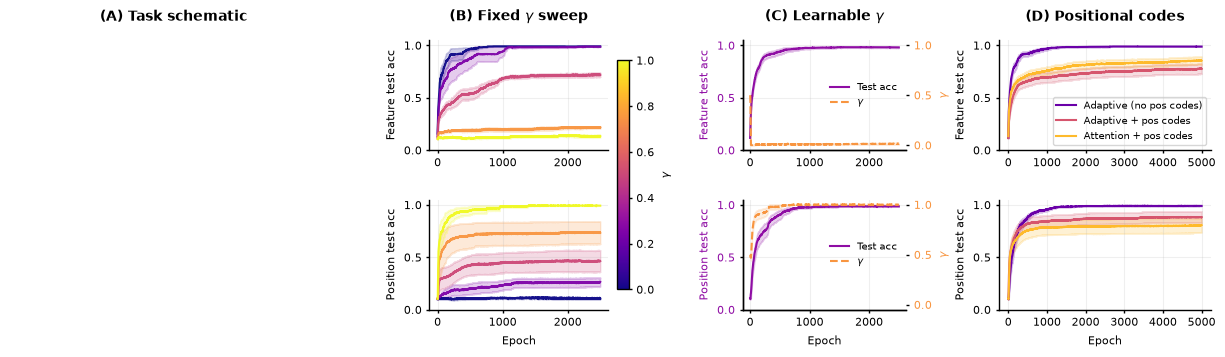

In [5]:
make_summary_figure(
    epoch_start=EPOCH_START,
    epoch_end=EPOCH_END,
    shade="sem",
    label_fontsize=8,
    legend_fontsize=7,
    tick_fontsize=8,
)

## Positional codes — individual trajectories

Standalone reproduction of `pos_codes_comparison_accuracy.png` from
`plot_pos_codes_comparison_results.py` (3 rows = conditions, 2 cols = label modes,
faint lines = per-seed trajectories, bold line = mean ± SEM).

Saved → ../results/pos_codes_comparison_accuracy.pdf


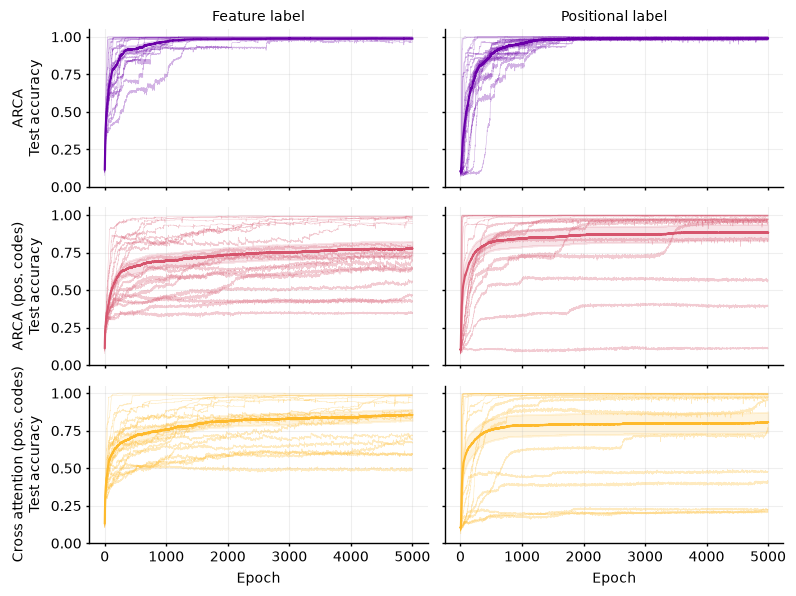

In [9]:
def make_pos_codes_trajectories_figure(
    results_path = POS_CODES_RESULTS_PATH,
    save_path    = "../results/pos_codes_comparison_accuracy.pdf",
    shade        = "sem",
    label_fontsize = 8,
    tick_fontsize   = 8,
):
    results = load_json(results_path)

    fig, axes = plt.subplots(
        len(POS_CONDITIONS), len(LABEL_MODES),
        figsize=(8, 6), sharey=True, sharex=True,
    )

    for row, cond in enumerate(POS_CONDITIONS):
        for col, mode in enumerate(LABEL_MODES):
            ax = axes[row, col]
            seed_dict = results[cond][mode]
            curves    = collect_curves(seed_dict, "test_acc")
            epochs    = np.arange(curves.shape[1])
            color     = POS_CONDITION_COLORS[cond]

            plot_individual_trajectories(ax, epochs, curves, color=color)
            plot_mean_sem_curve(ax, epochs, curves, color=color, shade=shade)

            if row == 0:
                ax.set_title(POS_COL_TITLES[mode], fontsize=10)
            if col == 0:
                ax.set_ylabel(f"{POS_ROW_LABELS[cond]}\nTest accuracy", fontsize=label_fontsize)
            if row == len(POS_CONDITIONS) - 1:
                ax.set_xlabel("Epoch", fontsize=label_fontsize)

            ax.set_ylim(0.0, 1.05)
            ax.grid(alpha=0.2)
            ax.tick_params(axis="both", labelsize=tick_fontsize)

    plt.tight_layout()

    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(save_path)
    print(f"Saved → {save_path}")
    plt.show()


make_pos_codes_trajectories_figure(
    shade="sem",
    label_fontsize=10,
    tick_fontsize=10,
)

## Fixed $\gamma$ sweep — standalone (1×2)

Just panel (B) from the summary figure, extracted into its own 1-row × 2-col figure
(feature label, position label), reusing `fill_fixed_gamma_col`.

Saved → ../results/fixed_gamma_sweep_figure.pdf


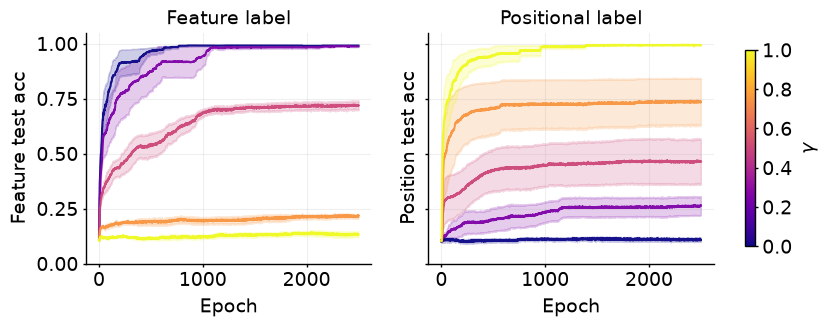

In [7]:
def make_fixed_gamma_figure(
    results_path = FIXED_RESULTS_PATH,
    save_path    = "../results/fixed_gamma_sweep_figure.pdf",
    gammas       = None,
    shade        = "sem",
    label_fontsize = 8,
    tick_fontsize   = 8,
):
    results = load_json(results_path)

    if gammas is None:
        first_lm = LABEL_MODES[0]
        gammas = sorted(float(k) for k in results[first_lm][ATTN_KIND].keys())

    fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
    cmap, norm = fill_fixed_gamma_col(
        axes, results, gammas, shade,
        label_fontsize=label_fontsize, tick_fontsize=tick_fontsize,
    )

    for ax, mode in zip(axes, LABEL_MODES):
        ax.set_title(POS_COL_TITLES[mode], fontsize=label_fontsize)
        ax.set_xlabel("Epoch", fontsize=label_fontsize)

    sm = ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=axes, location="right", pad=0.04, shrink=0.85)
    cbar.set_label("$\\gamma$", fontsize=label_fontsize)
    cbar.ax.tick_params(labelsize=tick_fontsize)

    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, bbox_inches="tight")
    print(f"Saved → {save_path}")
    plt.show()


make_fixed_gamma_figure(
    shade="sem",
    label_fontsize=14,
    tick_fontsize=14,
)

## Learnable $\gamma$ — standalone (1×2)

Just panel (C) from the summary figure, extracted into its own 1-row × 2-col figure
(feature label, position label), reusing `fill_online_gamma_col`.

Saved → ../results/online_gamma_figure.pdf


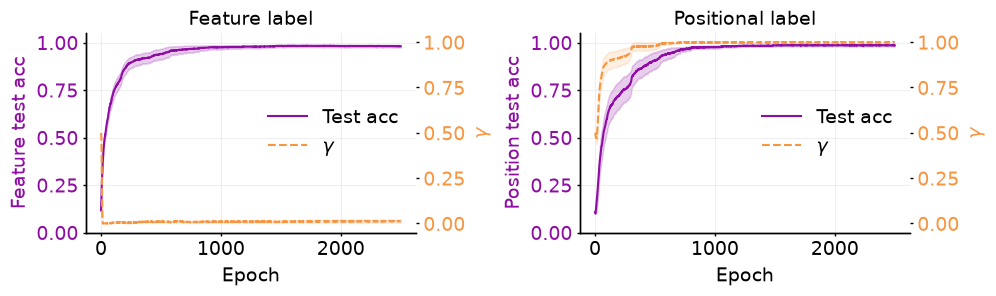

In [8]:
def make_online_gamma_figure(
    results_path = ONLINE_RESULTS_PATH,
    save_path    = "../results/online_gamma_figure.pdf",
    epoch_start  = EPOCH_START,
    epoch_end    = EPOCH_END,
    shade        = "sem",
    label_fontsize  = 8,
    legend_fontsize = 7,
    tick_fontsize   = 8,
):
    results = load_json(results_path)

    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    fill_online_gamma_col(
        axes, results, epoch_start, epoch_end, shade,
        label_fontsize=label_fontsize, legend_fontsize=legend_fontsize, tick_fontsize=tick_fontsize,
    )

    for ax, mode in zip(axes, LABEL_MODES):
        ax.set_title(POS_COL_TITLES[mode], fontsize=label_fontsize)
        ax.set_xlabel("Epoch", fontsize=label_fontsize)

    Path(save_path).parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(save_path)
    print(f"Saved → {save_path}")
    plt.show()


make_online_gamma_figure(
    shade="sem",
    label_fontsize=14,
    legend_fontsize=14,
    tick_fontsize=14,
)